# AgentAuthZ Analyst v2: fine-tuning Llama-3.2-3B with Unsloth

**Task:** decide **ALLOW / STEP_UP / DENY** for (a) real human login events from the RBA dataset (Wiefling et al., 33M SSO logins), and (b) AI-agent delegation and MCP tool-call events (synthetic, rule-labeled). The model first writes a **checks** trace (agent status, act claim, audience, scopes, approval, geo, login novelty…), then the decision, risk score, reasons, controls, and sources when policy context is supplied.

**v2 vs v1:** v1 learned the format but defaulted to ALLOW on agent attacks. v2 adds the checks-before-decision trace, 2.5× more agent examples with more multi-fault cases, and explicit `act: null`.

**Before you run:** set **Runtime → Change runtime type → T4 GPU**. Upload `train.jsonl` and `eval.jsonl` with the 📁 Files panel. Then choose **Runtime → Run all**.

| Cell | Screenshot |
|---|---|
| 2. Preview dataset | `01_dataset.png` |
| 5. Train | `02_training_loss.png` |
| 6. Compare base vs fine-tuned | `03`–`05` (side-by-side) |

## 1. Install Unsloth

In [1]:
%%capture
!pip install unsloth

## 2. Preview dataset

In [2]:
import json, pandas as pd
from datasets import load_dataset
pd.set_option("display.max_colwidth", 140)

ds = load_dataset("json", data_files={"train": "train.jsonl", "eval": "eval.jsonl"})
print(ds)

def flat(r):
    ev = r["messages"][1]["content"].split("EVENT:\n", 1)[1]
    return {"source": r["source"], "decision": r["decision"],
            "event (input)": ev[:140] + "…", "target (output)": r["messages"][2]["content"][:140] + "…"}

df = pd.DataFrame([flat(r) for r in ds["train"]])
display(pd.crosstab(df["source"], df["decision"], margins=True))
display(df.groupby("source").sample(4, random_state=1))

Generating train split: 0 examples [00:00, ? examples/s]

Generating eval split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['source', 'decision', 'messages'],
        num_rows: 1269
    })
    eval: Dataset({
        features: ['source', 'decision', 'messages'],
        num_rows: 141
    })
})


decision,ALLOW,DENY,STEP_UP,All
source,,,,
rba_login,135,135,135,405
synthetic_agent,225,225,225,675
synthetic_agent_rag,63,63,63,189
All,423,423,423,1269


,source,decision,event (input),target (output)
1134,rba_login,DENY,"{""event_type"":""human_login"",""primary_credential"":""valid"",""hour_local"":21,""country"":""PL"",""asn"":""49787"",""browser_os"":""Chrome Mobile 81.0.4...","{""checks"": {""ip_reputation"": ""known_attack_source"", ""first_login"": false, ""new_country"": false, ""new_asn"": true, ""new_browser_os"": true,..."
171,rba_login,STEP_UP,"{""event_type"":""human_login"",""primary_credential"":""valid"",""hour_local"":13,""country"":""NO"",""asn"":""15659"",""browser_os"":""Chrome 80.0.3987.240...","{""checks"": {""ip_reputation"": ""no_known_threat"", ""first_login"": false, ""new_country"": false, ""new_asn"": true, ""new_browser_os"": true, ""ne..."
991,rba_login,DENY,"{""event_type"":""human_login"",""primary_credential"":""valid"",""hour_local"":8,""country"":""US"",""asn"":""393398"",""browser_os"":""Chrome Mobile 81.0.4...","{""checks"": {""ip_reputation"": ""known_attack_source"", ""first_login"": false, ""new_country"": false, ""new_asn"": false, ""new_browser_os"": fals..."
240,rba_login,DENY,"{""event_type"":""human_login"",""primary_credential"":""valid"",""hour_local"":11,""country"":""RO"",""asn"":""206801"",""browser_os"":""Chrome 79.0.3945.19...","{""checks"": {""ip_reputation"": ""known_attack_source"", ""first_login"": false, ""new_country"": true, ""new_asn"": true, ""new_browser_os"": true, ..."
609,synthetic_agent,DENY,"{""event_type"":""agent_tool_call"",""user"":{""id"":""u-2841"",""roles"":[""finance_analyst""],""mfa_age_min"":106},""agent"":{""id"":""po-assistant-13"",""re...","{""checks"": {""agent_registered"": false, ""agent_status"": ""active"", ""act_claim"": ""ok"", ""audience"": ""mismatch"", ""scopes_within_delegation"": ..."
1054,synthetic_agent,STEP_UP,"{""event_type"":""agent_tool_call"",""user"":{""id"":""u-4696"",""roles"":[""iam_admin""],""mfa_age_min"":70},""agent"":{""id"":""invoice-bot-11"",""registered...","{""checks"": {""agent_registered"": true, ""agent_status"": ""active"", ""act_claim"": ""ok"", ""audience"": ""ok"", ""scopes_within_delegation"": true, ""..."
266,synthetic_agent,ALLOW,"{""event_type"":""agent_tool_call"",""user"":{""id"":""u-2027"",""roles"":[""finance_analyst""],""mfa_age_min"":47},""agent"":{""id"":""audit-helper-01"",""reg...","{""checks"": {""agent_registered"": true, ""agent_status"": ""active"", ""act_claim"": ""ok"", ""audience"": ""ok"", ""scopes_within_delegation"": true, ""..."
1158,synthetic_agent,DENY,"{""event_type"":""agent_tool_call"",""user"":{""id"":""u-8708"",""roles"":[""finance_approver""],""mfa_age_min"":81},""agent"":{""id"":""returns-triage-12"",""...","{""checks"": {""agent_registered"": true, ""agent_status"": ""active"", ""act_claim"": ""ok"", ""audience"": ""ok"", ""scopes_within_delegation"": true, ""..."
726,synthetic_agent_rag,STEP_UP,"{""event_type"":""agent_tool_call"",""user"":{""id"":""u-8589"",""roles"":[""admin""],""mfa_age_min"":183},""agent"":{""id"":""ship-planner-08"",""registered"":...","{""checks"": {""agent_registered"": true, ""agent_status"": ""active"", ""act_claim"": ""ok"", ""audience"": ""ok"", ""scopes_within_delegation"": true, ""..."
254,synthetic_agent_rag,ALLOW,"{""event_type"":""agent_tool_call"",""user"":{""id"":""u-5441"",""roles"":[""finance_analyst""],""mfa_age_min"":156},""agent"":{""id"":""po-assistant-15"",""re...","{""checks"": {""agent_registered"": true, ""agent_status"": ""active"", ""act_claim"": ""ok"", ""audience"": ""ok"", ""scopes_within_delegation"": true, ""..."


## 3. Load base model and record BASE answers to the 3 comparison questions

In [3]:
from unsloth import FastLanguageModel
from unsloth.chat_templates import get_chat_template
import torch

max_seq_length = 2048
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name="unsloth/Llama-3.2-3B-Instruct",
    max_seq_length=max_seq_length, load_in_4bit=True)
tokenizer = get_chat_template(tokenizer, chat_template="llama-3.1")

SYSTEM = ds["train"][0]["messages"][0]["content"]
QUESTIONS = json.loads(r'''[
 {
  "id": "Q1",
  "title": "Q1 human login: new country/ASN/browser at 03:00 after failures",
  "prompt": "Assess this event and return the authorization decision as JSON.\n\nEVENT:\n{\"event_type\":\"human_login\",\"primary_credential\":\"valid\",\"hour_local\":3,\"country\":\"BR\",\"asn\":\"28573\",\"browser_os\":\"Chrome 79.0 | Windows 10\",\"device_type\":\"desktop\",\"rtt_ms\":742,\"ip_reputation\":\"no_known_threat\",\"history\":{\"prior_logins\":37,\"country_seen_before\":false,\"asn_seen_before\":false,\"browser_os_seen_before\":false,\"device_type_seen_before\":true,\"failed_attempts_24h\":4}}",
  "expected": {
   "checks": {
    "ip_reputation": "no_known_threat",
    "first_login": false,
    "new_country": true,
    "new_asn": true,
    "new_browser_os": true,
    "new_device_type": false,
    "failed_attempts_24h": 4
   },
   "decision": "STEP_UP",
   "risk": 80,
   "reasons": [
    "new country BR for this user",
    "new network ASN 28573",
    "new browser/OS combination",
    "4 failed attempts in last 24h"
   ],
   "controls": [
    "Risk-based authentication (IP/ASN/country/device novelty)",
    "NIST SP 800-63B rate limiting of failed attempts"
   ]
  }
 },
 {
  "id": "Q2",
  "title": "Q2 agent: payment.release with no act claim and escalated scope",
  "prompt": "Assess this event and return the authorization decision as JSON.\n\nEVENT:\n{\"event_type\":\"agent_tool_call\",\"user\":{\"id\":\"u-2210\",\"roles\":[\"finance_analyst\"],\"mfa_age_min\":30},\"agent\":{\"id\":\"invoice-bot-08\",\"registered\":true,\"state\":\"active\",\"owner\":\"u-2210\",\"type\":\"interactive\"},\"token\":{\"grant_type\":\"urn:ietf:params:oauth:grant-type:token-exchange\",\"sub\":\"u-2210\",\"act\":null,\"aud\":\"https://mcp.erp.example/\",\"scopes\":[\"orders:read\",\"payments:write\"],\"age_min\":5,\"jti_seen_before\":false},\"delegated_scopes\":[\"orders:read\",\"reports:read\"],\"tool_call\":{\"mcp_server\":\"erp-mcp\",\"tool\":\"payment.release\",\"target_resource\":\"https://mcp.erp.example/\",\"reversible\":false,\"data_sensitivity\":\"financial\",\"records\":1},\"human_approval\":\"none\",\"context\":{\"hour_local\":10,\"runtime_geo\":\"US\",\"usual_geo\":\"US\",\"delegation_depth\":1}}",
  "expected": {
   "checks": {
    "agent_registered": true,
    "agent_status": "active",
    "act_claim": "missing",
    "audience": "ok",
    "scopes_within_delegation": false,
    "user_entitled": false,
    "token_replay": false,
    "token_age_ok": true,
    "chain_depth_ok": true,
    "irreversible_unapproved": true,
    "bulk_sensitive": false,
    "geo": "usual",
    "hour_ok": true,
    "mfa_fresh": true
   },
   "decision": "DENY",
   "risk": 99,
   "reasons": [
    "token has sub=user but no act claim: impersonation, not delegation",
    "token scopes exceed user delegation: payments:write",
    "user role 'finance_analyst' is not entitled to payment.release; an agent cannot exceed its user",
    "payment.release is irreversible and human approval is 'none'"
   ],
   "controls": [
    "RFC 8693 token exchange (act claim / delegation)",
    "OWASP LLM06:2025 Excessive Agency",
    "Least privilege: agent scopes <= delegated <= user entitlements",
    "Human-in-the-loop: Verify & Act for irreversible actions"
   ]
  }
 },
 {
  "id": "Q3",
  "title": "Q3 agent: external email (irreversible) with approval pending",
  "prompt": "Assess this event and return the authorization decision as JSON.\n\nEVENT:\n{\"event_type\":\"agent_tool_call\",\"user\":{\"id\":\"u-5531\",\"roles\":[\"warehouse_manager\"],\"mfa_age_min\":30},\"agent\":{\"id\":\"cust-support-03\",\"registered\":true,\"state\":\"active\",\"owner\":\"u-5531\",\"type\":\"interactive\"},\"token\":{\"grant_type\":\"urn:ietf:params:oauth:grant-type:token-exchange\",\"sub\":\"u-5531\",\"act\":{\"sub\":\"cust-support-03\"},\"aud\":\"https://mcp.mail.example/\",\"scopes\":[\"email:send\"],\"age_min\":5,\"jti_seen_before\":false},\"delegated_scopes\":[\"customers:read\",\"email:send\",\"orders:read\"],\"tool_call\":{\"mcp_server\":\"mail-mcp\",\"tool\":\"email.send_external\",\"target_resource\":\"https://mcp.mail.example/\",\"reversible\":false,\"data_sensitivity\":\"internal\",\"records\":1},\"human_approval\":\"pending\",\"context\":{\"hour_local\":10,\"runtime_geo\":\"US\",\"usual_geo\":\"US\",\"delegation_depth\":1}}",
  "expected": {
   "checks": {
    "agent_registered": true,
    "agent_status": "active",
    "act_claim": "ok",
    "audience": "ok",
    "scopes_within_delegation": true,
    "user_entitled": true,
    "token_replay": false,
    "token_age_ok": true,
    "chain_depth_ok": true,
    "irreversible_unapproved": true,
    "bulk_sensitive": false,
    "geo": "usual",
    "hour_ok": true,
    "mfa_fresh": true
   },
   "decision": "STEP_UP",
   "risk": 45,
   "reasons": [
    "email.send_external is irreversible and human approval is 'pending'"
   ],
   "controls": [
    "Human-in-the-loop: Verify & Act for irreversible actions"
   ]
  }
 }
]''')

def ask(prompt, max_new_tokens=512):
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": prompt}]
    ids = tokenizer.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt").to("cuda")
    out = model.generate(input_ids=ids, max_new_tokens=max_new_tokens, do_sample=False,
                         pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0][ids.shape[1]:], skip_special_tokens=True).strip()

FastLanguageModel.for_inference(model)
base_answers = {q["id"]: ask(q["prompt"]) for q in QUESTIONS}
for q in QUESTIONS:
    print(f"=== {q['id']} BASE ===\n{base_answers[q['id']]}\n")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.9.14: Fast Llama patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Unsloth: Will load unsloth/Llama-3.2-3B-Instruct-unsloth-bnb-4bit as a legacy tokenizer.
The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (ht

=== Q1 BASE ===
```json
{
  "checks": {
    "credential_validity": true,
    "ip_reputation": "no_known_threat",
    "device_type": "allowed",
    "country": "allowed",
    "asn": "allowed",
    "browser_os": "allowed",
    "device_history": "allowed",
    "failed_attempts_24h": "allowed"
  },
  "decision": "ALLOW",
  "risk": 20,
  "reasons": [
    "Valid credential",
    "No known threat IP",
    "Device type allowed",
    "Country allowed",
    "ASN allowed",
    "Browser OS allowed",
    "Device history allowed",
    "Failed attempts 24h allowed"
  ],
  "controls": [
    "Multi-Factor Authentication (MFA) not required",
    "Device history not required",
    "Country and ASN not required",
    "Browser OS not required"
  ],
  "sources": [
    "login_policy.json",
    "ip_reputation_service.json",
    "device_type_policy.json",
    "country_policy.json",
    "asn_policy.json",
    "browser_os_policy.json"
  ]
}
```

=== Q2 BASE ===
```json
{
  "checks": {
    "user_id": "u-2210",
   

## 4. Add LoRA adapters and format the chat data

In [4]:
model = FastLanguageModel.get_peft_model(
    model, r=16, lora_alpha=16, lora_dropout=0, bias="none",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    use_gradient_checkpointing="unsloth", random_state=3407)
FastLanguageModel.for_training(model)

def fmt(batch):
    return {"text": [tokenizer.apply_chat_template(m, tokenize=False, add_generation_prompt=False)
                     for m in batch["messages"]]}

train_ds = ds["train"].map(fmt, batched=True, remove_columns=ds["train"].column_names)
print(len(train_ds), "training rows\n")
print(train_ds[0]["text"][-900:])

Unsloth 2026.9.14 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Map:   0%|          | 0/1269 [00:00<?, ? examples/s]

1269 training rows

turn the authorization decision as JSON.

EVENT:
{"event_type":"human_login","primary_credential":"valid","hour_local":16,"country":"NO","asn":"41164","browser_os":"Chrome 72.0.3626.69 | Mac OS X 10.14.6","device_type":"desktop","rtt_ms":null,"ip_reputation":"no_known_threat","history":{"prior_logins":1,"country_seen_before":true,"asn_seen_before":false,"browser_os_seen_before":false,"device_type_seen_before":false,"failed_attempts_24h":0}}<|eot_id|><|start_header_id|>assistant<|end_header_id|>

{"checks": {"ip_reputation": "no_known_threat", "first_login": false, "new_country": false, "new_asn": true, "new_browser_os": true, "new_device_type": true, "failed_attempts_24h": 0}, "decision": "STEP_UP", "risk": 60, "reasons": ["new network ASN 41164", "new browser/OS combination", "new device type desktop"], "controls": ["Risk-based authentication (IP/ASN/country/device novelty)"]}<|eot_id|>


## 5. Train (loss is logged every 5 steps and plotted)

Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/1269 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Map:   0%|          | 0/1269 [00:00<?, ? examples/s]

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 1,269 | Num Epochs = 2 | Total steps = 318
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 24,313,856 of 3,237,063,680 (0.75% trained)
`use_return_dict` is deprecated! Use `return_dict` instead!


Unsloth: Will smartly offload gradients to save VRAM!


/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:5429: UserWarning: 'has_cuda' is deprecated, please use 'torch.backends.cuda.is_built()'
  return original(name)
/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:5429: UserWarning: 'has_cudnn' is deprecated, please use 'torch.backends.cudnn.is_available()'
  return original(name)
/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:5429: UserWarning: 'has_mps' is deprecated, please use 'torch.backends.mps.is_built()'
  return original(name)
/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:5429: UserWarning: 'has_mkldnn' is deprecated, please use 'torch.backends.mkldnn.is_available()'
  return original(name)


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss
5,2.099791
10,1.485783
15,0.817714
20,0.402959
25,0.383468
30,0.189439
35,0.087580
40,0.085063
45,0.081974
50,0.044605


Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-318/tokenizer_config.json.


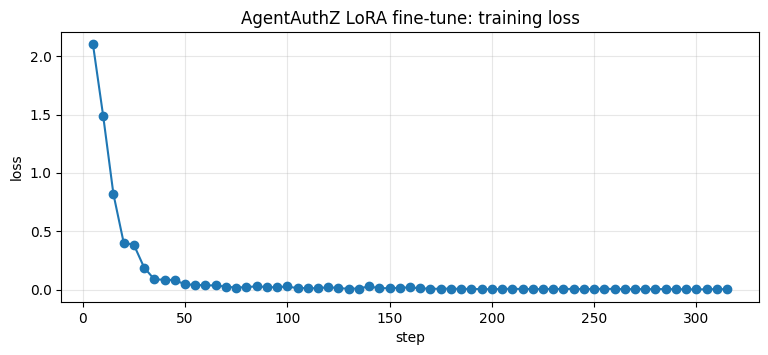

runtime 2918s | first loss 2.100 -> final loss 0.003


In [5]:
from trl import SFTTrainer, SFTConfig
from unsloth.chat_templates import train_on_responses_only
import matplotlib.pyplot as plt

cfg = dict(dataset_text_field="text",
           per_device_train_batch_size=2, gradient_accumulation_steps=4,
           warmup_steps=10, num_train_epochs=2, learning_rate=2e-4,
           logging_steps=5, optim="adamw_8bit", weight_decay=0.01,
           lr_scheduler_type="linear", seed=3407, output_dir="outputs", report_to="none")
# v2 answers are longer (checks trace first); allow 2048 tokens. The arg name differs across TRL versions.
try:
    sft_args = SFTConfig(max_length=2048, **cfg)
except TypeError:
    sft_args = SFTConfig(max_seq_length=2048, **cfg)
trainer = SFTTrainer(model=model, tokenizer=tokenizer, train_dataset=train_ds, args=sft_args)
# Learn only the analyst's answer, not the event text.
trainer = train_on_responses_only(
    trainer,
    instruction_part="<|start_header_id|>user<|end_header_id|>\n\n",
    response_part="<|start_header_id|>assistant<|end_header_id|>\n\n")

stats = trainer.train()

logs = [l for l in trainer.state.log_history if "loss" in l]
plt.figure(figsize=(9, 3.5))
plt.plot([l["step"] for l in logs], [l["loss"] for l in logs], marker="o")
plt.title("AgentAuthZ LoRA fine-tune: training loss"); plt.xlabel("step"); plt.ylabel("loss"); plt.grid(alpha=.3)
plt.show()
print(f"runtime {stats.metrics['train_runtime']:.0f}s | first loss {logs[0]['loss']:.3f} -> final loss {logs[-1]['loss']:.3f}")

## 6. Compare base vs fine-tuned (same 3 questions)

In [6]:
from IPython.display import HTML, display
import html

FastLanguageModel.for_inference(model)
ft_answers = {q["id"]: ask(q["prompt"]) for q in QUESTIONS}

for q in QUESTIONS:
    ev = q["prompt"].split("EVENT:\n", 1)[1]
    display(HTML(f'''
    <h3>{q['id']}: {html.escape(q['title'])}</h3>
    <details><summary>event JSON</summary><pre style="white-space:pre-wrap">{html.escape(ev)}</pre></details>
    <table style="width:100%;table-layout:fixed;border:1px solid #999">
      <tr><th style="text-align:left">BASE: Llama-3.2-3B-Instruct</th><th style="text-align:left">FINE-TUNED: AgentAuthZ</th></tr>
      <tr><td style="vertical-align:top"><pre style="white-space:pre-wrap">{html.escape(base_answers[q['id']])}</pre></td>
          <td style="vertical-align:top"><pre style="white-space:pre-wrap">{html.escape(ft_answers[q['id']])}</pre></td></tr>
    </table>
    <p><b>Expected (rule engine):</b> {q['expected']['decision']}, risk {q['expected']['risk']}</p>'''))

Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


BASE: Llama-3.2-3B-Instruct,FINE-TUNED: AgentAuthZ
"```json { ""checks"": { ""credential_validity"": true, ""ip_reputation"": ""no_known_threat"", ""device_type"": ""allowed"", ""country"": ""allowed"", ""asn"": ""allowed"", ""browser_os"": ""allowed"", ""device_history"": ""allowed"", ""failed_attempts_24h"": ""allowed"" }, ""decision"": ""ALLOW"", ""risk"": 20, ""reasons"": [ ""Valid credential"", ""No known threat IP"", ""Device type allowed"", ""Country allowed"", ""ASN allowed"", ""Browser OS allowed"", ""Device history allowed"", ""Failed attempts 24h allowed"" ], ""controls"": [ ""Multi-Factor Authentication (MFA) not required"", ""Device history not required"", ""Country and ASN not required"", ""Browser OS not required"" ], ""sources"": [ ""login_policy.json"", ""ip_reputation_service.json"", ""device_type_policy.json"", ""country_policy.json"", ""asn_policy.json"", ""browser_os_policy.json"" ] } ```","{""checks"": {""ip_reputation"": ""no_known_threat"", ""first_login"": false, ""new_country"": true, ""new_asn"": true, ""new_browser_os"": true, ""new_device_type"": false, ""failed_attempts_24h"": 4}, ""decision"": ""STEP_UP"", ""risk"": 75, ""reasons"": [""new country BR for this user"", ""new network ASN 28573"", ""new browser/OS combination""], ""controls"": [""Risk-based authentication (IP/ASN/country/device novelty)""]}"


BASE: Llama-3.2-3B-Instruct,FINE-TUNED: AgentAuthZ
"```json { ""checks"": { ""user_id"": ""u-2210"", ""user_roles"": [""finance_analyst""], ""agent_type"": ""interactive"", ""agent_state"": ""active"", ""token_grant_type"": ""urn:ietf:params:oauth:grant-type:token-exchange"", ""token_scopes"": [""orders:read"", ""payments:write""], ""delegated_scopes"": [""orders:read"", ""reports:read""], ""mfa_age_min"": 30, ""human_approval"": ""none"", ""context"": { ""hour_local"": 10, ""runtime_geo"": ""US"", ""usual_geo"": ""US"", ""delegation_depth"": 1 } }, ""decision"": ""ALLOW"", ""risk"": 20, ""reasons"": [ ""User has sufficient roles"", ""User is not in a high-risk context"", ""No human approval required for this tool call"" ], ""controls"": [ ""Role-Based Access Control"", ""Delegation Depth Limitation"" ], ""sources"": [ ""mcp_tool_call.json"", ""user_info.json"" ] } ```","{""checks"": {""agent_registered"": true, ""agent_status"": ""active"", ""act_claim"": ""missing"", ""audience"": ""ok"", ""scopes_within_delegation"": false, ""user_entitled"": true, ""token_replay"": false, ""token_age_ok"": true, ""chain_depth_ok"": true, ""irreversible_unapproved"": true, ""bulk_sensitive"": false, ""geo"": ""usual"", ""hour_ok"": true, ""mfa_fresh"": true}, ""decision"": ""DENY"", ""risk"": 99, ""reasons"": [""token has sub=user but no act claim: impersonation, not delegation"", ""payment.release is irreversible and human approval is 'none'"", ""token scopes exceed user delegation: payments:write""], ""controls"": [""RFC 8693 token exchange (act claim / delegation)"", ""Human-in-the-loop: Verify & Act for irreversible actions""]}"


BASE: Llama-3.2-3B-Instruct,FINE-TUNED: AgentAuthZ
"```json { ""checks"": { ""user_id"": ""u-5531"", ""user_roles"": [""warehouse_manager""], ""agent_type"": ""interactive"", ""agent_state"": ""active"", ""agent_owner"": ""u-5531"", ""token_grant_type"": ""urn:ietf:params:oauth:grant-type:token-exchange"", ""token_sub"": ""u-5531"", ""token_aud"": ""https://mcp.mail.example/"", ""token_scopes"": [""email:send""], ""delegated_scopes"": [""customers:read"", ""email:send"", ""orders:read""], ""tool_call_mcp_server"": ""mail-mcp"", ""tool_call_tool"": ""email.send_external"", ""tool_call_target_resource"": ""https://mcp.mail.example/"", ""tool_call_reversible"": false, ""tool_call_data_sensitivity"": ""internal"", ""tool_call_records"": 1, ""human_approval"": ""pending"", ""context_hour_local"": 10, ""context_runtime_geo"": ""US"", ""context_usual_geo"": ""US"", ""context_delegation_depth"": 1 }, ""decision"": ""ALLOW"", ""risk"": 20, ""reasons"": [ ""User has sufficient roles for the requested action"", ""Agent is registered and active"", ""Token is valid and has sufficient scopes"", ""Tool call is reversible and has internal data sensitivity"", ""Delegation depth is within acceptable limits"" ], ""controls"": [ ""Role-Based Access Control (RBAC)"", ""Agent Registration and Activation"", ""Token Validation and Scopes"", ""Reversible Tool Calls"", ""Delegation Depth Limitation"" ], ""sources"": [ ""user_id_check.py"", ""role_check.py"", ""agent_check.py"", ""token_check.py"", ""tool_call_check.py"", ""human_approval_check.py"", ""context_check.py"" ] } ```","{""checks"": {""agent_registered"": true, ""agent_status"": ""active"", ""act_claim"": ""ok"", ""audience"": ""ok"", ""scopes_within_delegation"": true, ""user_entitled"": true, ""token_replay"": false, ""token_age_ok"": true, ""chain_depth_ok"": true, ""irreversible_unapproved"": true, ""bulk_sensitive"": false, ""geo"": ""usual"", ""hour_ok"": true, ""mfa_fresh"": true}, ""decision"": ""STEP_UP"", ""risk"": 45, ""reasons"": [""email.send_external is irreversible and human approval is 'pending'""], ""controls"": [""Human-in-the-loop: Verify & Act for irreversible actions""]}"


## 7. Quick held-out check (fine-tuned model)
The full base-vs-fine-tuned evaluation runs locally against Ollama (`eval/run_compare.py`).

In [7]:
import re, collections
N = 60
rows = ds["eval"].select(range(min(N, len(ds["eval"]))))
hits, valid, per = 0, 0, collections.Counter()
for r in rows:
    out = ask(r["messages"][1]["content"], max_new_tokens=512)
    m = re.search(r"\{.*\}", out, re.S)
    pred = None
    try:
        pred = json.loads(m.group(0))["decision"]; valid += 1
    except Exception:
        pass
    ok = pred == r["decision"]; hits += ok; per[(r["source"], ok)] += 1
print(f"FT decision accuracy {hits}/{len(rows)} = {hits/len(rows):.0%} | valid JSON {valid}/{len(rows)}")
print(dict(per))

Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_

FT decision accuracy 60/60 = 100% | valid JSON 60/60
{('rba_login', True): 20, ('synthetic_agent_rag', True): 7, ('synthetic_agent', True): 33}


## 8. Export GGUF for Ollama (q4_k_m, ≈2 GB). Then right-click `agentauthz-q4_k_m.gguf` in Files → Download

In [8]:
import glob, shutil, os
model.save_pretrained("agentauthz_lora"); tokenizer.save_pretrained("agentauthz_lora")   # small LoRA adapter
model.save_pretrained_gguf("agentauthz_gguf", tokenizer, quantization_method="q4_k_m")
cands = [p for p in glob.glob("**/*.gguf", recursive=True) if "q4_k_m" in p.lower()]
print(cands)
shutil.copy(cands[0], "agentauthz-q4_k_m.gguf")
print(f"agentauthz-q4_k_m.gguf  {os.path.getsize('agentauthz-q4_k_m.gguf')/1e9:.2f} GB")

Unsloth: Restored added_tokens_decoder metadata in agentauthz_lora/tokenizer_config.json.
Unsloth: ##### The current model auto adds a BOS token.
Unsloth: ##### Your chat template has a BOS token. We shall remove it temporarily.


Unsloth: Merging model weights to 16-bit format...


config.json:   0%|          | 0.00/890 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/20.9k [00:00<?, ?B/s]

Unsloth: Restored added_tokens_decoder metadata in agentauthz_gguf/tokenizer_config.json.


...

Note: tokenizer.model not found (this is OK for non-SentencePiece models)


Unsloth: Merging weights into 16bit: 100%|██████████| 2/2 [02:31<00:00, 75.68s/it]


Unsloth: Merge process complete. Saved to `/content/agentauthz_gguf`
Unsloth: Converting to GGUF format...
==((====))==  Unsloth: Conversion from HF to GGUF information
   \\   /|    [0] Installing llama.cpp might take 3 minutes.
O^O/ \_/ \    [1] Converting HF to GGUF f16 might take 3 minutes.
\        /    [2] Converting GGUF f16 to ['q4_k_m'] might take 10 minutes each.
 "-____-"     In total, you will have to wait at least 16 minutes.

Unsloth: Installing llama.cpp. This might take 3 minutes...
Unsloth: Installing prebuilt llama.cpp b11408-mix-1e24fc5 (app-b11408-mix-1e24fc5-linux-x64-cpu.tar.gz) - skipping compilation.
Unsloth: Preparing converter script...
Unsloth: [1] Converting model into f16 GGUF format.
This might take 3 minutes...
Unsloth: Initial conversion completed! Files: ['agentauthz_gguf_gguf/Llama-3.2-3B-Instruct.F16.gguf']
Unsloth: [2] Converting GGUF f16 into q4_k_m. This might take 10 minutes...
Unsloth: Model files cleanup...


Unsloth: ##### The current model auto adds a BOS token.
Unsloth: ##### We removed it in GGUF's chat template for you.


Unsloth: All GGUF conversions completed successfully!
Generated files: ['agentauthz_gguf_gguf/Llama-3.2-3B-Instruct.Q4_K_M.gguf']
Unsloth: example usage for text only LLMs: /root/.unsloth/llama.cpp/llama-cli --model agentauthz_gguf_gguf/Llama-3.2-3B-Instruct.Q4_K_M.gguf -p "why is the sky blue?"
Unsloth: Saved Ollama Modelfile to agentauthz_gguf_gguf/Modelfile
Unsloth: convert model to ollama format by running - ollama create model_name -f agentauthz_gguf_gguf/Modelfile
['agentauthz_gguf_gguf/Llama-3.2-3B-Instruct.Q4_K_M.gguf']
agentauthz-q4_k_m.gguf  2.02 GB
